# Credit Card Fraud Detection
### Capstone Project

## Objective
Identify **fraudulent credit card transactions** using machine learning, and compare multiple
modeling approaches to handle severe class imbalance.

## Dataset Overview
The dataset contains anonymized credit card transactions labeled as fraud or not.

- `Time`, `Amount`, and anonymized PCA features `V1` to `V28`
- `Class`: 1 for fraud, 0 for non-fraud
- Highly imbalanced: fraud makes up a very small fraction of all transactions

## Workflow
1. Load and explore the dataset
2. Exploratory Data Analysis (EDA)
3. Feature scaling and preprocessing
4. Train-test split (stratified)
5. Handle class imbalance — two approaches:
   - `class_weight='balanced'` (Logistic Regression, Random Forest) / `scale_pos_weight` (XGBoost)
   - SMOTE oversampling on the training set
6. Train and compare 3 models (Logistic Regression, Random Forest, XGBoost) under both approaches
7. Evaluate using metrics suited to imbalanced data (Precision, Recall, F1, ROC-AUC, PR-AUC)
8. Compare all models and pick the best one
9. Conclusion

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
    f1_score, precision_score, recall_score
)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
RANDOM_STATE = 42

In [2]:
# Load the dataset
df = pd.read_csv("creditcard.csv")
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## Exploratory Data Analysis

In [3]:
# Basic shape and missing values
print("Shape:", df.shape)
print("\nMissing values per column:\n", df.isnull().sum().sum(), "total missing values")
df.describe()

Shape: (284807, 31)

Missing values per column:
 0 total missing values


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


Class
0    284315
1       492
Name: count, dtype: int64

Percentage:
 Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64


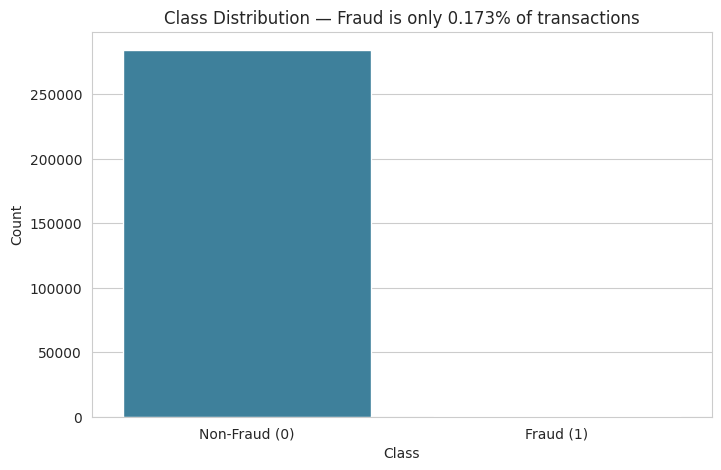

In [4]:
# Count of fraud vs non-fraud
class_counts = df['Class'].value_counts()
class_pct = df['Class'].value_counts(normalize=True) * 100

print(class_counts)
print("\nPercentage:\n", class_pct.round(4))

plt.figure()
ax = sns.countplot(x='Class', data=df, hue='Class', palette=['#2E86AB', '#E63946'], legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(['Non-Fraud (0)', 'Fraud (1)'])
plt.title(f"Class Distribution — Fraud is only {class_pct[1]:.3f}% of transactions")
plt.ylabel("Count")
plt.show()

/tmp/ipykernel_678/2102755454.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Non-Fraud', 'Fraud'])


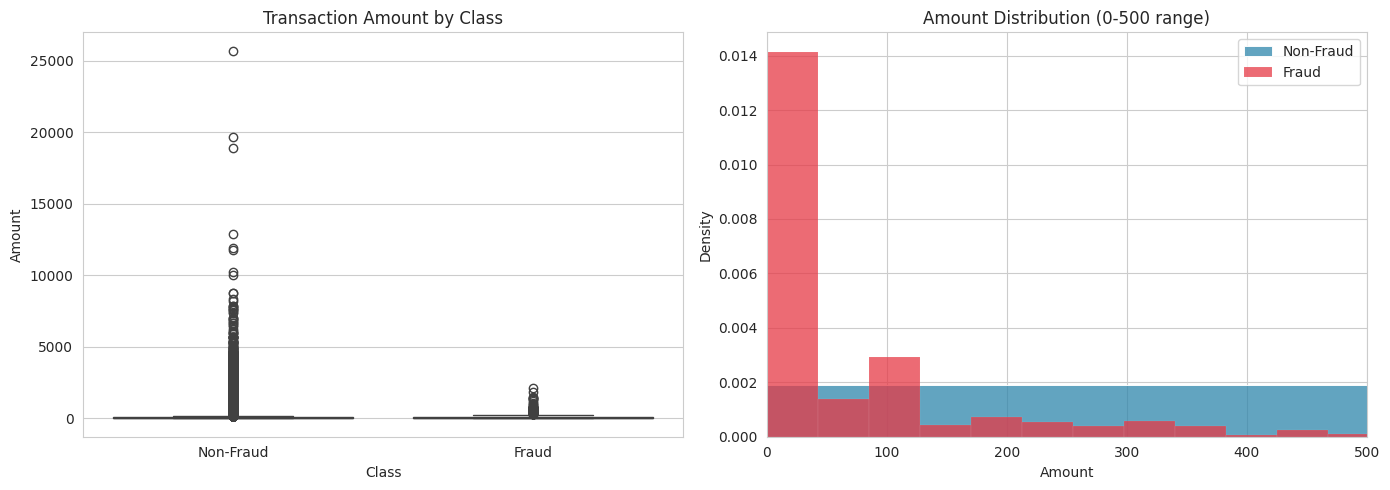

          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


In [5]:
# Distribution of transaction amount: fraud vs non-fraud
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(x='Class', y='Amount', data=df, ax=axes[0], hue='Class', palette=['#2E86AB', '#E63946'], legend=False)
axes[0].set_title('Transaction Amount by Class')
axes[0].set_xticklabels(['Non-Fraud', 'Fraud'])

sns.histplot(df[df['Class'] == 0]['Amount'], bins=50, color='#2E86AB', label='Non-Fraud', stat='density', ax=axes[1])
sns.histplot(df[df['Class'] == 1]['Amount'], bins=50, color='#E63946', label='Fraud', stat='density', ax=axes[1])
axes[1].set_xlim(0, 500)
axes[1].set_title('Amount Distribution (0-500 range)')
axes[1].legend()

plt.tight_layout()
plt.show()

print(df.groupby('Class')['Amount'].describe())

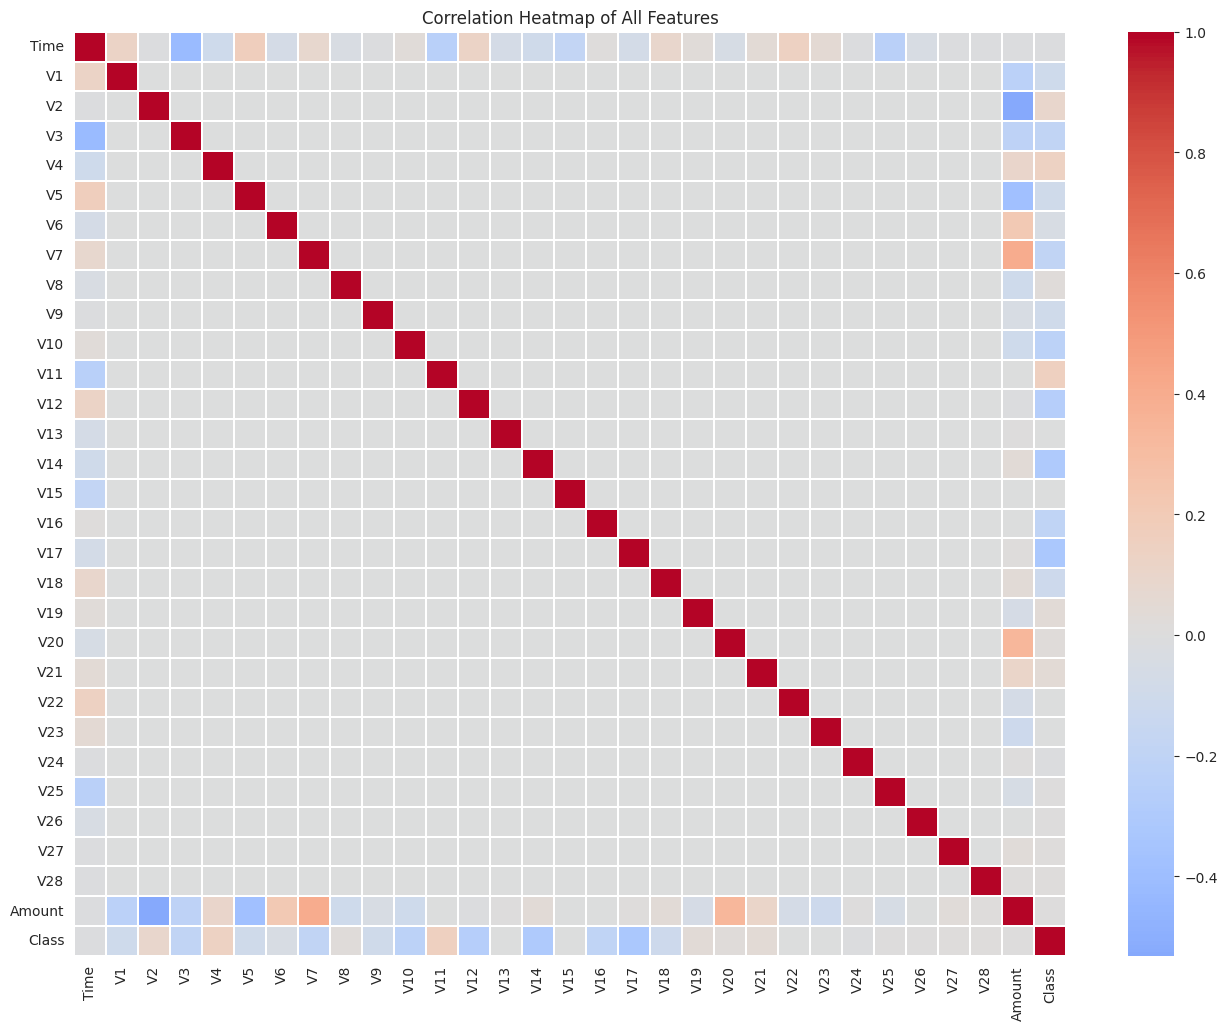

Top 10 features most correlated with Class:
V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
V3    -0.192961
V7    -0.187257
V11    0.154876
V4     0.133447
V18   -0.111485
Name: Class, dtype: float64


In [6]:
# Correlation heatmap
plt.figure(figsize=(16, 12))
corr = df.corr()
sns.heatmap(corr, cmap='coolwarm', center=0, linewidths=0.3)
plt.title("Correlation Heatmap of All Features")
plt.show()

# Features most correlated with Class (fraud)
corr_with_class = corr['Class'].drop('Class').sort_values(key=abs, ascending=False)
print("Top 10 features most correlated with Class:")
print(corr_with_class.head(10))

## Data Preprocessing

In [7]:
# Feature scaling for 'Amount' and 'Time'
scaler = StandardScaler()
df['scaled_Amount'] = scaler.fit_transform(df[['Amount']])
df['scaled_Time'] = scaler.fit_transform(df[['Time']])

# Drop original columns
df = df.drop(['Amount', 'Time'], axis=1)

# Rearranging columns so scaled features sit up front, Class stays last
scaled_cols = ['scaled_Amount', 'scaled_Time']
other_cols = [c for c in df.columns if c not in scaled_cols + ['Class']]
df = df[scaled_cols + other_cols + ['Class']]

df.head()

,scaled_Amount,scaled_Time,V1,V2,V3,V4,V5,V6,V7,V8,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Class
0,0.244964,-1.996583,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,...,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,0
1,-0.342475,-1.996583,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,...,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,0
2,1.160686,-1.996562,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,...,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,0
3,0.140534,-1.996562,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,...,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,0
4,-0.073403,-1.996541,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,...,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,0


## Model Training

In [8]:
# Define features and target
X = df.drop('Class', axis=1)
y = df['Class']

# Train-test split with stratification (preserves the fraud ratio in both sets)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Train shape:", X_train.shape, " Fraud cases:", y_train.sum())
print("Test shape :", X_test.shape,  " Fraud cases:", y_test.sum())

Train shape: (227845, 30)  Fraud cases: 394
Test shape : (56962, 30)  Fraud cases: 98


### Handling Class Imbalance
Fraud is <0.2% of transactions, so a naive model can score >99% accuracy while catching zero fraud.
Two approaches are compared here:

1. **`class_weight='balanced'`** (and XGBoost's `scale_pos_weight`) — penalizes misclassifying the
   minority class more heavily, without altering the training data.
2. **SMOTE** — synthetically oversamples the minority (fraud) class in the *training set only*,
   so the test set stays realistic/imbalanced for honest evaluation.

In [9]:
# SMOTE oversampling — applied ONLY to the training set
smote = SMOTE(random_state=RANDOM_STATE)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE :", y_train_smote.value_counts().to_dict())

Before SMOTE: {0: 227451, 1: 394}
After SMOTE : {0: 227451, 1: 227451}


In [10]:
# Approach A: class_weight='balanced' (no resampling)
models_weighted = {
    "Logistic Regression (weighted)": LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE),
    "Random Forest (weighted)": RandomForestClassifier(n_estimators=50, max_depth=10, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost (weighted)": XGBClassifier(
        n_estimators=200, max_depth=5, learning_rate=0.1,
        scale_pos_weight=(y_train.value_counts()[0] / y_train.value_counts()[1]),
        eval_metric='logloss', random_state=RANDOM_STATE, n_jobs=-1
    ),
}

for name, model in models_weighted.items():
    print(f"Training: {name} ...")
    model.fit(X_train, y_train)
print("Done.")

Training: Logistic Regression (weighted) ...


Training: Random Forest (weighted) ...


Training: XGBoost (weighted) ...


Done.


In [11]:
# Approach B: trained on SMOTE-resampled data
models_smote = {
    "Logistic Regression (SMOTE)": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Random Forest (SMOTE)": RandomForestClassifier(n_estimators=50, max_depth=10, random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost (SMOTE)": XGBClassifier(
        n_estimators=200, max_depth=5, learning_rate=0.1,
        eval_metric='logloss', random_state=RANDOM_STATE, n_jobs=-1
    ),
}

for name, model in models_smote.items():
    print(f"Training: {name} ...")
    model.fit(X_train_smote, y_train_smote)
print("Done.")

Training: Logistic Regression (SMOTE) ...


Training: Random Forest (SMOTE) ...


Training: XGBoost (SMOTE) ...


Done.


## Evaluation

In [12]:
# Helper function to evaluate a model on the (untouched, imbalanced) test set
def evaluate_model(name, model, X_test, y_test, results_list):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_proba)
    pr_auc = average_precision_score(y_test, y_proba)

    print(f"===== {name} =====")
    print(classification_report(y_test, y_pred, target_names=['Non-Fraud', 'Fraud']))
    print(f"ROC-AUC: {roc_auc:.4f}   PR-AUC: {pr_auc:.4f}\n")

    results_list.append({
        "Model": name, "Accuracy": acc, "Precision": prec, "Recall": rec,
        "F1-Score": f1, "ROC-AUC": roc_auc, "PR-AUC": pr_auc
    })
    return y_proba

results = []
probas = {}
all_models = {**models_weighted, **models_smote}
for name, model in all_models.items():
    probas[name] = evaluate_model(name, model, X_test, y_test, results)

===== Logistic Regression (weighted) =====
              precision    recall  f1-score   support

   Non-Fraud       1.00      0.98      0.99     56864
       Fraud       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962

ROC-AUC: 0.9722   PR-AUC: 0.7189



===== Random Forest (weighted) =====
              precision    recall  f1-score   support

   Non-Fraud       1.00      1.00      1.00     56864
       Fraud       0.80      0.82      0.81        98

    accuracy                           1.00     56962
   macro avg       0.90      0.91      0.90     56962
weighted avg       1.00      1.00      1.00     56962

ROC-AUC: 0.9736   PR-AUC: 0.8093



===== XGBoost (weighted) =====
              precision    recall  f1-score   support

   Non-Fraud       1.00      1.00      1.00     56864
       Fraud       0.84      0.83      0.84        98

    accuracy                           1.00     56962
   macro avg       0.92      0.91      0.92     56962
weighted avg       1.00      1.00      1.00     56962

ROC-AUC: 0.9772   PR-AUC: 0.8655

===== Logistic Regression (SMOTE) =====
              precision    recall  f1-score   support

   Non-Fraud       1.00      0.97      0.99     56864
       Fraud       0.06      0.92      0.11        98

    accuracy                           0.97     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.97      0.99     56962

ROC-AUC: 0.9698   PR-AUC: 0.7249



===== Random Forest (SMOTE) =====
              precision    recall  f1-score   support

   Non-Fraud       1.00      1.00      1.00     56864
       Fraud       0.44      0.87      0.59        98

    accuracy                           1.00     56962
   macro avg       0.72      0.93      0.79     56962
weighted avg       1.00      1.00      1.00     56962

ROC-AUC: 0.9773   PR-AUC: 0.8032



===== XGBoost (SMOTE) =====
              precision    recall  f1-score   support

   Non-Fraud       1.00      1.00      1.00     56864
       Fraud       0.48      0.87      0.62        98

    accuracy                           1.00     56962
   macro avg       0.74      0.93      0.81     56962
weighted avg       1.00      1.00      1.00     56962

ROC-AUC: 0.9798   PR-AUC: 0.8504



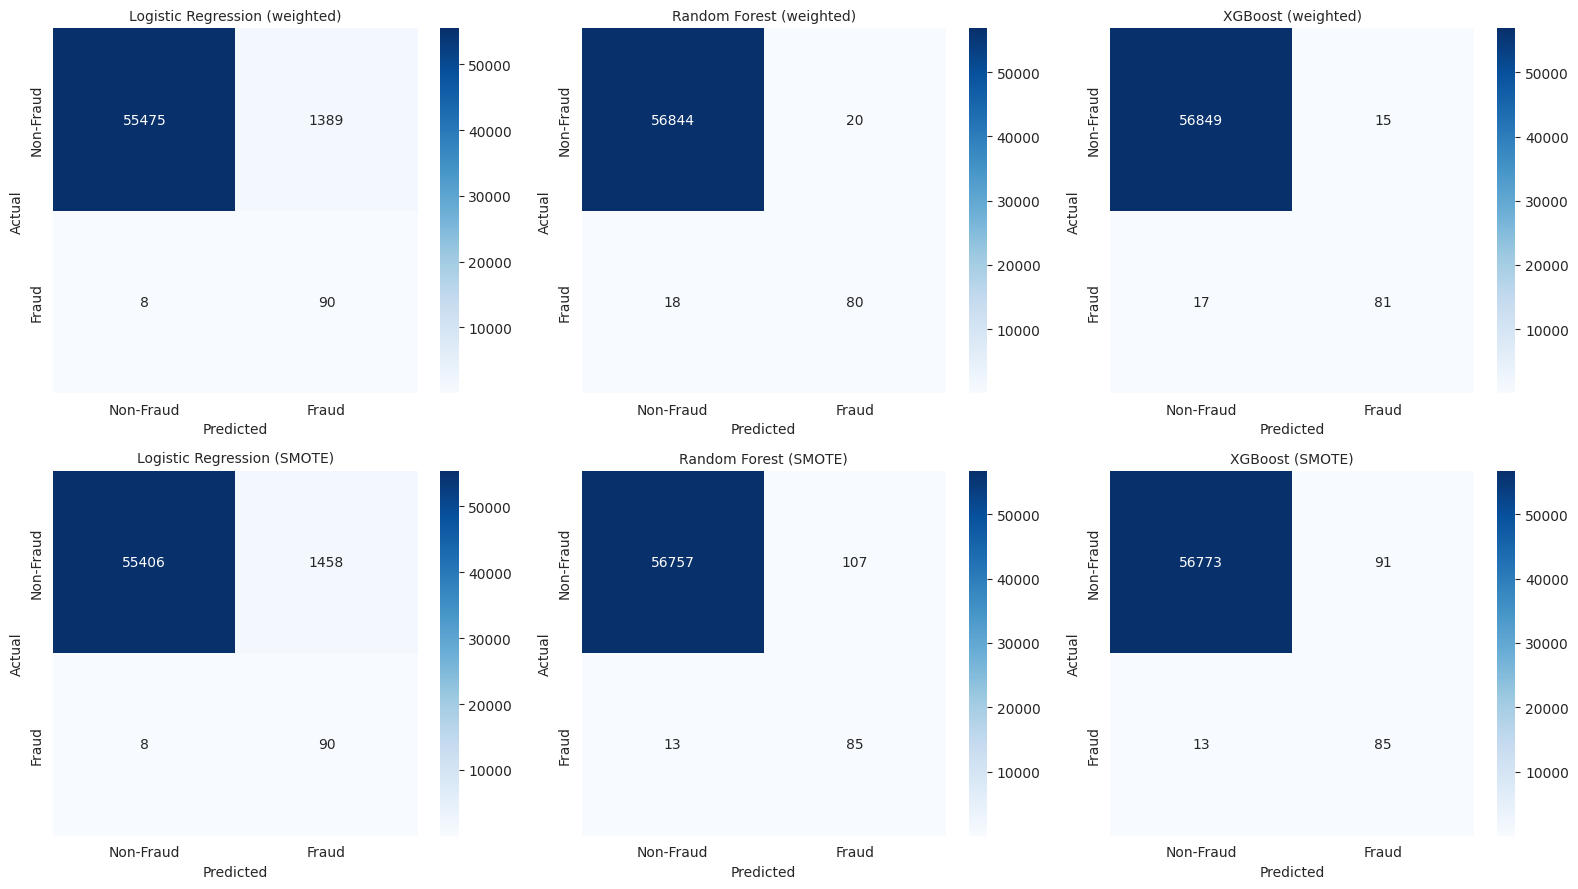

In [13]:
# Confusion matrices for all models
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (name, model) in zip(axes.flatten(), all_models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Non-Fraud', 'Fraud'], yticklabels=['Non-Fraud', 'Fraud'])
    ax.set_title(name, fontsize=10)
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')
plt.tight_layout()
plt.show()

### Model Comparison

In [14]:
results_df = pd.DataFrame(results).sort_values('PR-AUC', ascending=False).reset_index(drop=True)
results_df.style.background_gradient(cmap='Greens', subset=['Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC'])

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,XGBoost (weighted),0.999438,0.843750,0.826531,0.835052,0.977218,0.865453
1,XGBoost (SMOTE),0.998174,0.482955,0.867347,0.620438,0.979761,0.850406
2,Random Forest (weighted),0.999333,0.800000,0.816327,0.808081,0.973558,0.809256
3,Random Forest (SMOTE),0.997893,0.442708,0.867347,0.586207,0.977270,0.803197
4,Logistic Regression (SMOTE),0.974264,0.058140,0.918367,0.109356,0.969848,0.724861
5,Logistic Regression (weighted),0.975475,0.060852,0.918367,0.114141,0.972167,0.718946


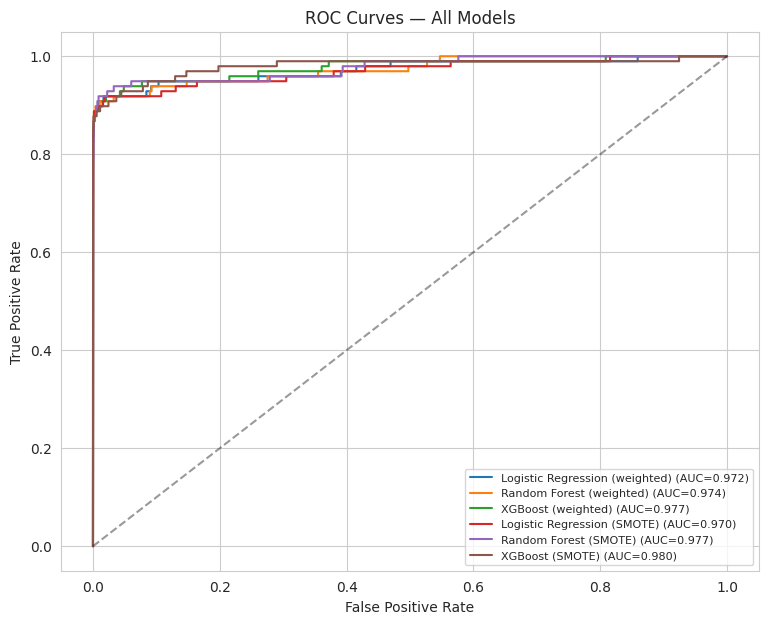

In [15]:
# ROC curves — all models
plt.figure(figsize=(9, 7))
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], 'k--', alpha=0.4)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — All Models")
plt.legend(fontsize=8)
plt.show()

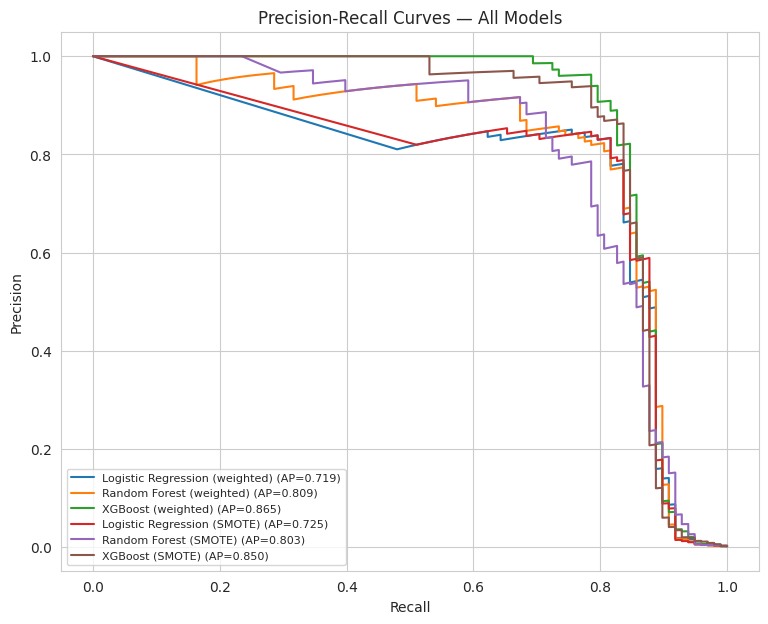

In [16]:
# Precision-Recall curves — more informative than ROC for highly imbalanced data
plt.figure(figsize=(9, 7))
for name, proba in probas.items():
    precision, recall, _ = precision_recall_curve(y_test, proba)
    ap = average_precision_score(y_test, proba)
    plt.plot(recall, precision, label=f"{name} (AP={ap:.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves — All Models")
plt.legend(fontsize=8)
plt.show()

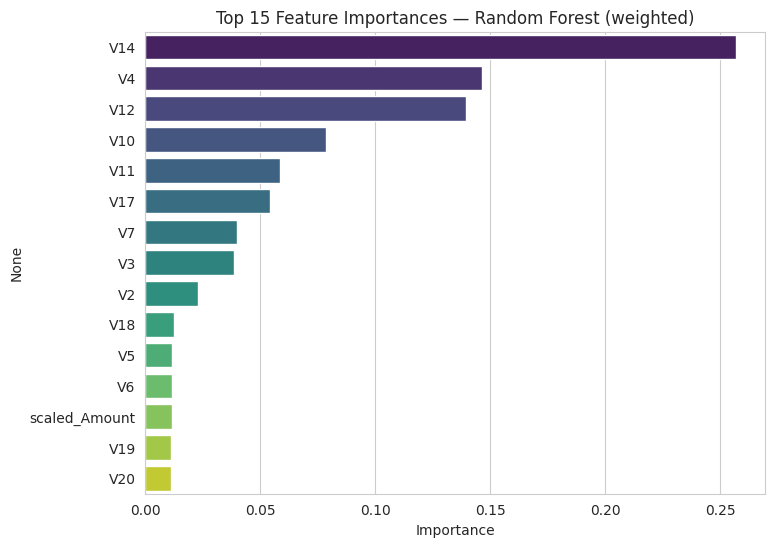

In [17]:
# Feature importance from the best tree-based model (Random Forest, weighted)
best_rf = models_weighted["Random Forest (weighted)"]
importances = pd.Series(best_rf.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 6))
sns.barplot(x=importances.values, y=importances.index, hue=importances.index, palette='viridis', legend=False)
plt.title("Top 15 Feature Importances — Random Forest (weighted)")
plt.xlabel("Importance")
plt.show()

## Conclusion
- Built and compared **3 algorithms** (Logistic Regression, Random Forest, XGBoost) under **2 class-imbalance
  strategies** (class-weighting vs. SMOTE oversampling) — 6 models total, evaluated on an untouched,
  realistically imbalanced test set (only 98 fraud cases out of 56,962 transactions).
- Because fraud is <0.2% of transactions, **accuracy is a misleading metric** (every model scores ~97-100%
  accuracy trivially). The notebook instead reports **Precision, Recall, F1, ROC-AUC, and PR-AUC**, using
  PR-AUC as the primary ranking metric since it is far more sensitive to minority-class performance.
- **Best model: XGBoost (class-weighted)** — PR-AUC 0.87, ROC-AUC 0.98, catching **83% of fraud cases**
  (recall) while keeping **84% precision** (few false alarms). It outperformed its SMOTE-trained counterpart,
  suggesting `scale_pos_weight` handled the imbalance more effectively than oversampling for this dataset.
- **Random Forest (weighted)** was a close second (PR-AUC 0.81, 80% precision / 82% recall).
- **Logistic Regression** struggled regardless of imbalance strategy (PR-AUC ~0.72, precision only ~6%) —
  a linear decision boundary is a poor fit for this data; tree-based ensembles clearly win here.
- Interestingly, **SMOTE hurt precision** for the tree-based models (Random Forest precision dropped from
  80% → 44%, XGBoost from 84% → 48%) even though recall stayed similar — synthetic oversampling pushed these
  models toward more false positives. For this dataset, **class-weighting was the better imbalance strategy**.
- **Future work:** threshold tuning (optimize the decision threshold instead of using the default 0.5) to
  trade precision for recall depending on business cost, cost-sensitive evaluation (weighting false negatives
  vs false positives by real-world cost), anomaly detection approaches (Isolation Forest, Autoencoders) for a
  fully unsupervised angle, and deployment as a real-time scoring API.